# Health — analysis (ADM2 panel)

Effect of upstream land-cover change on health in downstream municipalities. The
specification implements the decision table in §9 of
[`01_descriptives.ipynb`](01_descriptives.ipynb); the sample, outcome and exposure
construction lives in `src/analysis/health.py`.

**Baseline specification** (one regression per outcome, `pyfixest.fepois`):

```
count ~ alr_pasture + alr_agriculture + alr_farming_unclassified + alr_urban + alr_other        (upstream, ≤ 200 km)
      + local_alr_pasture + … + local_alr_other                                               (local)
      + local_2t + local_tp + local_swvl1
      + offset(log exposure)
  | municipality + state×year
```

| Element | Choice |
|---|---|
| Sample | municipality-years 2000–2024 with population and local climate (5,562 municipalities); headwater municipalities stay in with upstream ALR set to 0, absorbed by the municipality FE |
| Estimator | PPML on counts; exposure offset: population (hospitalizations), live births (infant and under-5 deaths), births with known weight / gestation (low birth weight / preterm) |
| Outcomes | primary: ICD 01 infectious/parasitic, ICD 11 digestive, gastrointestinal channel, infant deaths, low birth weight. Secondary: ICD 14, 16, 17; renal, skin, leptospirosis, toxic-poisoning, vector-borne channels; under-5 deaths; preterm (2012–2024). Placebo: ICD 19 injury/poisoning, injuries and mental-health channels |
| Exposure | upstream land cover in 25 km rings up to **200 km**, inv-sqrt kernel, next to the municipality's own (local) rings; ALR against natural land |
| Controls | local annual temperature, precipitation and top-layer soil moisture |
| Inference | cluster by Otto level-3 basin (`otto_basin_l3`); §8 compares state and Otto 4 and adds wild-cluster score-bootstrap p-values |

**Reading the coefficients.** ALR regressors are logs of the class-to-natural-land ratio
and PPML coefficients are on the log scale of the rate, so β is an elasticity: a 10%
higher pasture-to-natural ratio changes the rate by about β·10 %. §1 converts them to
effects of one within-municipality SD of exposure.

## Summary (run of 2026-10-22)

**Upstream land-cover change has no detectable effect on health in downstream
municipalities.** Identification rests on 0.4–2% of the exposure variation (descriptives
§4), but the PPML estimates are precise enough to rule out more than small effects.

- **Pasture and agriculture.** No upstream pasture or agriculture coefficient is
  significant for any primary outcome (infectious/parasitic, digestive, gastrointestinal
  hospitalizations, infant deaths, low birth weight). Per within-municipality SD of
  exposure, the 95% CIs exclude increases above about 0.6% (pasture) and 1.1%
  (agriculture) in every primary outcome. Most point estimates for water-related
  outcomes are negative.
- **No outcome responds more than the placebo.** No upstream coefficient differs from the
  injury placebo at 5% (stacked PPML, bootstrap). Where the differences come close
  (pasture and agriculture → infectious, p ≈ 0.05), the water outcome responds *less*
  than injuries.
- **Other classes.** 4 of 40 upstream coefficients pass the score bootstrap at 5%
  (2 expected by chance). Unclassified farming → low birth weight −0.7% and digestive
  +1.0% per SD, "other" land → infant deaths +0.7% per SD, and "other" → the
  mental-health placebo. None is part of a consistent pattern.
- **The local block absorbs confounding, as intended.** Local urbanization has the largest
  coefficients, and they are largest for the injury placebos (+0.23, +0.26). That points
  to local development and access to hospital care, not water. The one water-plausible
  local association is local pasture → gastrointestinal hospitalizations (+0.16,
  bootstrap p = 0.02), which exceeds the placebo only marginally (p = 0.06).
- **Robustness.** OLS on log rates, dropping 2020–21, the upstream climate block, the
  utilization control, 2008–2024 and municipalities with upstream rings only give the
  same picture. Municipality + biome×year FE make the injury placebo positive and
  significant (+0.09), which supports state×year FE. Distance bands and biome slopes show
  no water pattern. The clearest heterogeneity is in the placebo: frontier pasture
  (Amazon +0.25, Cerrado +0.20) goes with more injury hospitalizations.

Read together with the pollution arm (pasture → lead and cadmium violations, agriculture
→ COD), the measurable changes in river water quality do not translate into measurable
changes in these hospitalization, birth and mortality outcomes at municipality level.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfixest as pf

from src.analysis import descriptives as desc
from src.analysis import health as H
from src.analysis.inference import poisson_score_bootstrap

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# pyfixest drops singleton FE groups and separated observations by design;
# its per-model warnings would otherwise flood the output.
warnings.filterwarnings("ignore", message=r".*singleton fixed effect")
warnings.filterwarnings("ignore", message=r".*removed because of separation")

RESULTS_DIR = PROJECT_ROOT / "output" / "analysis" / "health"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

## 1. Estimation panel

In [2]:
df = H.build_health_panel(distance_bands=True)
municipalities = df.drop_duplicates("mun_id")
print(f"{len(df):,} municipality-years · {len(municipalities):,} municipalities "
      f"({(~municipalities['has_upstream']).sum()} headwater) · {df.year.min()}–{df.year.max()} · "
      f"{df['otto_basin_l3'].nunique()} Otto-3 basins")

ROLES = {**{n: "primary" for n in H.PRIMARY_OUTCOMES}, **{n: "secondary" for n in H.SECONDARY_OUTCOMES},
         **{n: "placebo" for n in H.PLACEBO_OUTCOMES}}
outcome_rows = {}
for name, (count, exposure) in H.OUTCOMES.items():
    observed = df[df[H.outcome_column(name)].notna() & df[H.offset_column(name)].notna()]
    y = observed[H.outcome_column(name)]
    outcome_rows[name] = {"role": ROLES[name], "count": count, "exposure": exposure, "n": len(observed),
                          "events per year": y.sum() / observed["year"].nunique(),
                          "rate per 1,000 exposure": 1000 * y.sum() / observed[exposure].sum(),
                          "share zero": (y == 0).mean()}
display(pd.DataFrame(outcome_rows).T)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

138,912 municipality-years · 5,562 municipalities (215 headwater) · 2000–2024 · 217 Otto-3 basins


,role,count,exposure,n,events per year,"rate per 1,000 exposure",share zero
infectious_parasitic,primary,hosp_icd_01,population,138912,9.469e+05,4.805,0.003347
digestive,primary,hosp_icd_11,population,138912,1.068e+06,5.419,0.001289
gastrointestinal,primary,hosp_water_sanitation_gastrointestinal,population,138912,3.721e+05,1.888,0.07209
infant_deaths,primary,deaths_under_1,births,138867,4.257e+04,14.75,0.2251
low_birth_weight,primary,births_low_weight,births_weight_known,138885,2.438e+05,84.73,0.02403
genitourinary,secondary,hosp_icd_14,population,138912,7.964e+05,4.042,0.002361
perinatal,secondary,hosp_icd_16,population,138912,2.517e+05,1.277,0.05799
congenital,secondary,hosp_icd_17,population,138912,8.281e+04,0.4202,0.1407
renal_urinary,secondary,hosp_renal_urinary_toxic_water,population,138912,4.837e+05,2.455,0.008466
skin_contact,secondary,hosp_skin_contact,population,138912,2.095e+05,1.063,0.07356


**Magnitudes.** Within-municipality SD of each exposure term after municipality +
state×year FE (upstream terms over municipalities with upstream rings), and the implied
effect of one SD for a coefficient of 0.1.

In [3]:
UPSTREAM, LOCAL = H.UPSTREAM_REGRESSORS, H.LOCAL_REGRESSORS
within_sd = pd.concat([
    desc.demean(df[df["has_upstream"]], UPSTREAM, ["mun_id", "state_year"]).std(),
    desc.demean(df, LOCAL, ["mun_id", "state_year"]).std(),
])
display(pd.DataFrame({"within SD": within_sd, "effect of 1 SD at β = 0.1 (%)": 100 * np.expm1(0.1 * within_sd)}).T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_other,local_alr_pasture,local_alr_agriculture,local_alr_farming_unclassified,local_alr_urban,local_alr_other
within SD,0.203,0.448,0.2726,0.1563,0.2959,0.184,0.4537,0.2609,0.1002,0.2764
effect of 1 SD at β = 0.1 (%),2.051,4.582,2.764,1.575,3.003,1.857,4.641,2.643,1.007,2.803


## 2. Specification

In [4]:
CONTROLS = H.CLIMATE_CONTROLS
RHS = " + ".join(UPSTREAM + LOCAL + CONTROLS)
FE = "mun_id + state_year"
VCOV = {"CRV1": "otto_basin_l3"}
PRIMARY, SECONDARY, PLACEBO = list(H.PRIMARY_OUTCOMES), list(H.SECONDARY_OUTCOMES), list(H.PLACEBO_OUTCOMES)


def fit(name, data=None, rhs=RHS, fe=FE, method="ppml"):
    # PPML on the count with a log-exposure offset; or OLS on the log rate of
    # positive counts, weighted by the exposure.
    data = df if data is None else data
    y, offset = H.outcome_column(name), H.offset_column(name)
    sample = data.dropna(subset=[y, offset])
    if method == "ppml":
        return pf.fepois(f"{y} ~ {rhs} | {fe}", data=sample, offset=offset, vcov=VCOV)
    sample = sample[sample[y] > 0].copy()
    sample["log_rate"] = np.log(sample[y]) - sample[offset]
    sample["exposure_weight"] = np.exp(sample[offset])
    return pf.feols(f"log_rate ~ {rhs} | {fe}", data=sample, weights="exposure_weight", vcov=VCOV)


def fit_all(names, **kwargs):
    fits = {}
    for name in names:
        try:
            fits[name] = fit(name, **kwargs)
        except Exception as error:  # report and continue; one sparse outcome should not stop the suite
            print(f"[{name}] failed: {error}")
    return fits


def tidy(fits, spec):
    rows = []
    for outcome, model in fits.items():
        table = model.tidy().reset_index()
        table["outcome"] = outcome
        table["spec"] = spec
        table["n_obs"] = model._N
        rows.append(table)
    return pd.concat(rows, ignore_index=True)

In [5]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # reference categorical slots 1-4, fixed order
SERIES_MARKERS = ["o", "s", "D", "^"]  # secondary encoding, so identity is not color alone


def coefficient_plot(table, coefficients, specs=None, title="", xlabel="coefficient (95% CI)"):
    # Dot-and-whisker small multiples: one panel per coefficient, outcomes on the y axis.
    specs = specs or table["spec"].unique().tolist()
    outcomes = table["outcome"].unique().tolist()
    fig, axes = plt.subplots(1, len(coefficients), figsize=(3.2 * len(coefficients), 0.34 * len(outcomes) + 1.4),
                             sharey=True, squeeze=False)
    for ax, coefficient in zip(axes[0], coefficients):
        for k, spec in enumerate(specs):
            sub = table[(table["Coefficient"] == coefficient) & (table["spec"] == spec)].set_index("outcome").reindex(outcomes)
            offset = (k - (len(specs) - 1) / 2) * 0.18
            ax.errorbar(sub["Estimate"], np.arange(len(outcomes)) + offset,
                        xerr=[sub["Estimate"] - sub["2.5%"], sub["97.5%"] - sub["Estimate"]],
                        fmt=SERIES_MARKERS[k], ms=6, lw=1.5, capsize=0, color=SERIES_COLORS[k], label=spec)
        ax.axvline(0, color="#8a8a85", lw=0.8, zorder=0)
        ax.grid(axis="x", color="#e6e6e3", lw=0.6)
        ax.set_title(coefficient, fontsize=9)
        ax.set_xlabel(xlabel, fontsize=8)
        ax.tick_params(labelsize=8)
    axes[0, 0].set_yticks(range(len(outcomes)), outcomes)
    axes[0, 0].invert_yaxis()
    if len(specs) > 1:
        fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="upper center", ncol=len(specs),
                   frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(title, y=1.06 if len(specs) > 1 else 1.0)
    plt.tight_layout()
    plt.show()

## 3. Baseline: primary and placebo outcomes

In [6]:
main_fits = fit_all(PRIMARY + PLACEBO)
main = tidy(main_fits, "baseline")
pf.etable(list(main_fits.values()), keep=UPSTREAM + LOCAL)

GT(_tbl_data=   __index_level_0__               __index_level_1__                      0                      1                     2                      3                       4                      5                      6  \
0               coef                     alr_pasture    -0.037 <br> (0.024)    -0.006 <br> (0.017)   -0.084 <br> (0.054)    -0.012 <br> (0.018)     -0.001 <br> (0.007)     0.024 <br> (0.029)     0.018 <br> (0.030)   
1               coef               local_alr_pasture    0.071* <br> (0.035)     0.015 <br> (0.031)  0.160** <br> (0.062)     0.020 <br> (0.016)     -0.002 <br> (0.009)     0.031 <br> (0.028)     0.033 <br> (0.029)   
2               coef                 alr_agriculture    -0.031 <br> (0.018)     0.003 <br> (0.011)   -0.030 <br> (0.022)    -0.013 <br> (0.008)      0.006 <br> (0.004)     0.015 <br> (0.018)     0.020 <br> (0.020)   
3               coef           local_alr_agriculture    -0.000 <br> (0.016)    -0.002 <br> (0.007)    0.027 <br> (0.020)    -0.008 <br> (0.006)    0.011** <br> (0.004)     0.010 <br> (0.011)     0.012 <br> (0.012)   
4               coef        alr_farming_unclassified     0.024 <br> (0.026)   0.037** <br> (0.014)    0.002 <br> (0.040)     0.001 <br> (0.013)  -0.025*** <br> (0.006)     0.006 <br> (0.020)     0.014 <br> (0.021)   
5               coef  local_alr_farming_unclassified   -0.045* <br> (0.021)   -0.036* <br> (0.014)   -0.043 <br> (0.030)  -0.031** <br> (0.011)      0.007 <br> (0.005)    -0.018 <br> (0.018)    -0.024 <br> (0.017)   
6               coef                       alr_urban    -0.061 <br> (0.036)    -0.039 <br> (0.022)   -0.067 <br> (0.049)    -0.001 <br> (0.018)      0.008 <br> (0.007)    -0.010 <br> (0.031)    -0.009 <br> (0.031)   
7               coef                 local_alr_urban  -0.257** <br> (0.079)  0.167*** <br> (0.048)   -0.107 <br> (0.133)    -0.056 <br> (0.039)   0.083*** <br> (0.020)  0.227*** <br> (0.041)  0.260*** <br> (0.046)   
8               coef                       alr_other     0.020 <br> (0.018)     0.008 <br> (0.011)    0.032 <br> (0.029)    0.023* <br> (0.009)      0.008 <br> (0.005)    -0.004 <br> (0.016)    -0.001 <br> (0.017)   
9               coef                 local_alr_other    -0.020 <br> (0.018)   -0.023* <br> (0.010)    0.035 <br> (0.027)    -0.012 <br> (0.009)    0.012** <br> (0.004)    0.025* <br> (0.012)    0.027* <br> (0.014)   
10                fe                      state_year                      x                      x                     x                      x                       x                      x                      x   
11                fe                         mun_id                       x                      x                     x                      x                       x                      x                      x   
12             stats                    Observations                138,887                138,887               138,875                138,792                 138,860                138,887                138,887   
13             stats                              R²                      -                      -                     -                      -                       -                      -                      -   

                        7  
0     -0.080 <br> (0.049)  
1     0.193* <br> (0.084)  
2      0.052 <br> (0.052)  
3     -0.027 <br> (0.058)  
4     -0.080 <br> (0.074)  
5     -0.060 <br> (0.077)  
6     -0.144 <br> (0.077)  
7     0.427* <br> (0.202)  
8   0.133*** <br> (0.036)  
9      0.072 <br> (0.049)  
10                      x  
11                      x  
12                138,675  
13                      -  , _body=<great_tables._gt_data.Body object at 0x7f03db841450>, _boxhead=Boxhead([ColInfo(var='__index_level_0__', type=<ColInfoTypeEnum.row_group: 3>, column_label='__index_level_0__', column_align='center', column_width=None), ColInfo(var='__index_level_1__', type=<ColInfoTypeEnum.stub: 2>, column_label='__ind

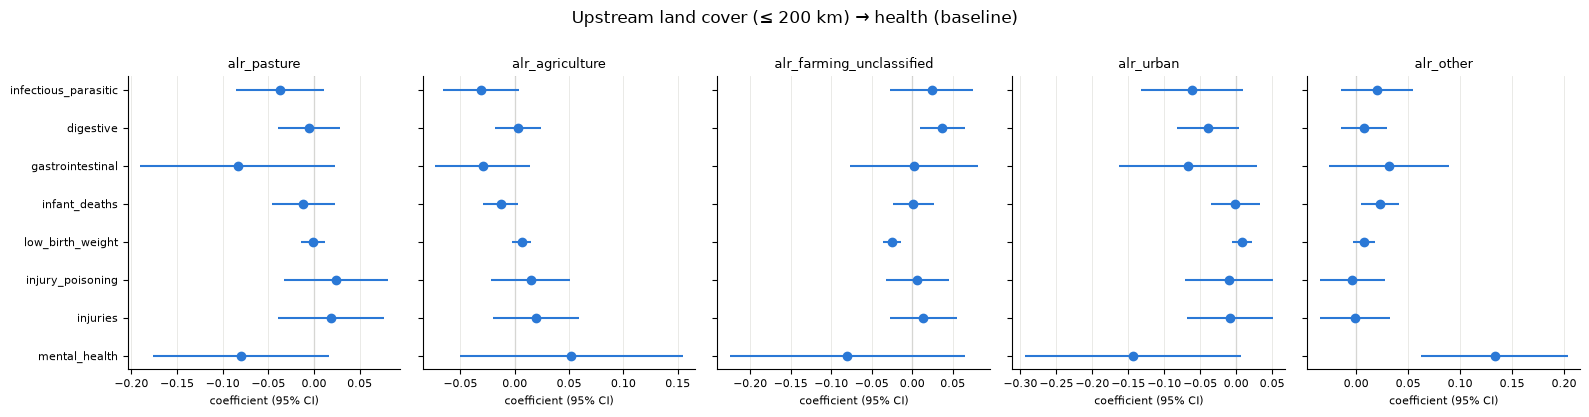

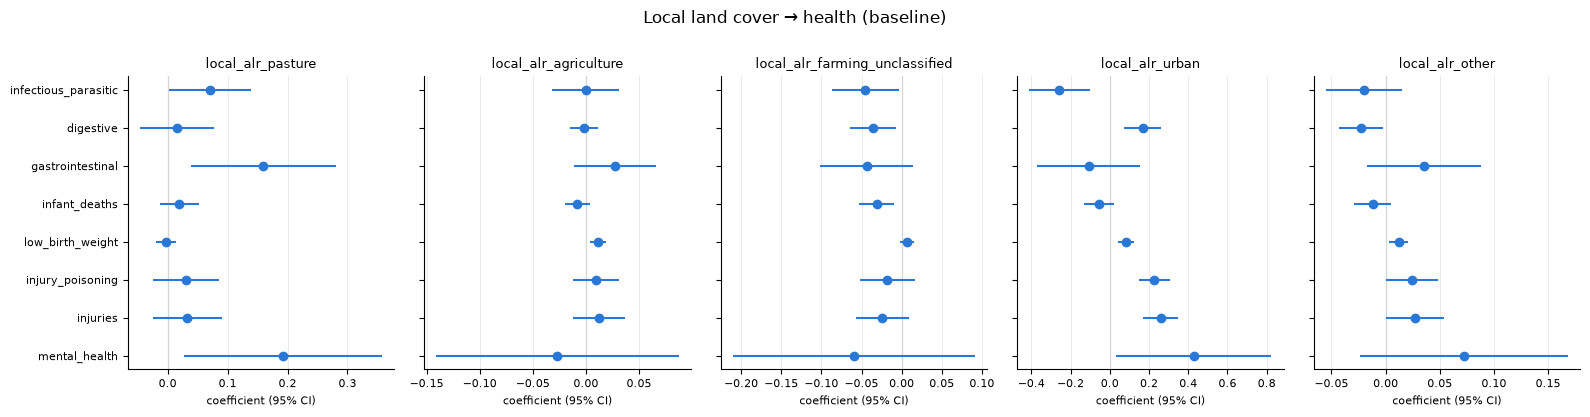

In [7]:
coefficient_plot(main, UPSTREAM, title="Upstream land cover (≤ 200 km) → health (baseline)")
coefficient_plot(main, LOCAL, title="Local land cover → health (baseline)")

**Reading the results (run of 2026-10-22).**
- **Upstream pasture and agriculture.** No coefficient is significant at 5% for any
  primary or placebo outcome. Most estimates for water-related outcomes are negative
  (pasture / agriculture: infectious −0.037 / −0.031, gastrointestinal −0.084 / −0.030,
  infant deaths −0.012 / −0.013), and the injury placebo's are positive (+0.024 / +0.015).
- **Precision.** Within-municipality SDs are 0.20 (pasture) and 0.45 (agriculture), so
  the 95% CIs exclude increases above about 0.6% and 1.1% per SD in every primary
  outcome (e.g. infant deaths: at most +0.5% per SD of pasture).
- **Other upstream classes.** Unclassified farming → digestive +0.037 and low birth
  weight −0.025; "other" non-natural land → infant deaths +0.023 and the mental-health
  placebo +0.13 (all p < 0.05).
- **Local block.** Local urbanization has the largest coefficients, and they are largest
  for the placebos (injury/poisoning +0.23, injuries +0.26). They are also large for
  digestive (+0.17), low birth weight (+0.08) and infectious (−0.26). This looks like
  local development and access to hospital care, not water. Local pasture →
  gastrointestinal (+0.16, SE 0.06) is the one water-plausible local association.

### 3.1 Difference from the placebo

Each primary outcome is stacked with the injury/poisoning placebo (ICD 19) in one PPML
fit with outcome-specific FE (municipality and state×year, each × outcome), and every
regressor also enters interacted with the primary-outcome indicator. PPML separates by
outcome, so the interaction coefficients equal the difference between the two separate
fits' coefficients exactly; Otto-3 clustering accounts for their correlation (same
municipalities and years). A water effect should differ from the placebo, not only from
zero.

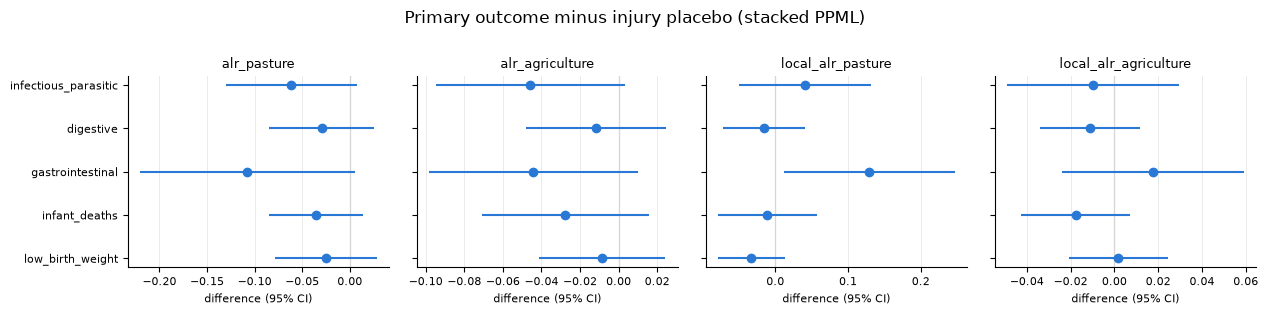

In [8]:
PLACEBO_REFERENCE = "injury_poisoning"
STACK_TERMS = UPSTREAM + LOCAL + CONTROLS
DIFF = {term: f"{term}_diff" for term in UPSTREAM + LOCAL}


def stacked(name, reference=PLACEBO_REFERENCE, data=None):
    # Long frame of `name` (is_outcome = 1) and the placebo (0), with interacted regressors and FE.
    data = df if data is None else data
    parts = []
    for outcome, is_outcome in [(name, 1), (reference, 0)]:
        part = data[["mun_id", "state_year", "otto_basin_l3", *STACK_TERMS]].copy()
        part["y"] = data[H.outcome_column(outcome)]
        part["log_exposure"] = data[H.offset_column(outcome)]
        part["is_outcome"] = is_outcome
        parts.append(part)
    long = pd.concat(parts, ignore_index=True).dropna(subset=["y", "log_exposure"])
    for term in STACK_TERMS:
        long[f"{term}_diff"] = long[term] * long["is_outcome"]
    flag = long["is_outcome"].astype(str)
    long["mun_stack"] = long["mun_id"] + "_" + flag
    long["state_year_stack"] = long["state_year"] + "_" + flag
    return long


RHS_STACKED = " + ".join(STACK_TERMS + [f"{term}_diff" for term in STACK_TERMS])
diff_fits = {name: pf.fepois(f"y ~ {RHS_STACKED} | mun_stack + state_year_stack", data=stacked(name),
                             offset="log_exposure", vcov=VCOV)
             for name in PRIMARY}
difference = tidy(diff_fits, "minus placebo")
difference = difference[difference["Coefficient"].isin(DIFF.values())].copy()
difference["Coefficient"] = difference["Coefficient"].str.removesuffix("_diff")
coefficient_plot(difference, ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"],
                 title="Primary outcome minus injury placebo (stacked PPML)", xlabel="difference (95% CI)")

**Reading the results (run of 2026-10-22).** No upstream coefficient differs from the injury placebo at 5%. The differences are mostly
negative, so water outcomes respond *less* to upstream pasture and agriculture than
injuries do. Examples: infectious minus placebo, pasture −0.061 (SE 0.035) and
agriculture −0.046 (0.025); gastrointestinal, pasture −0.108 (0.058). Local pasture →
gastrointestinal exceeds the placebo by +0.13 (SE 0.06; bootstrap p = 0.057, §8.2). The
significant local differences involve urban and "other" land, with every primary outcome
below the placebo: the placebo's stronger response to local urbanization.

## 4. Secondary outcomes

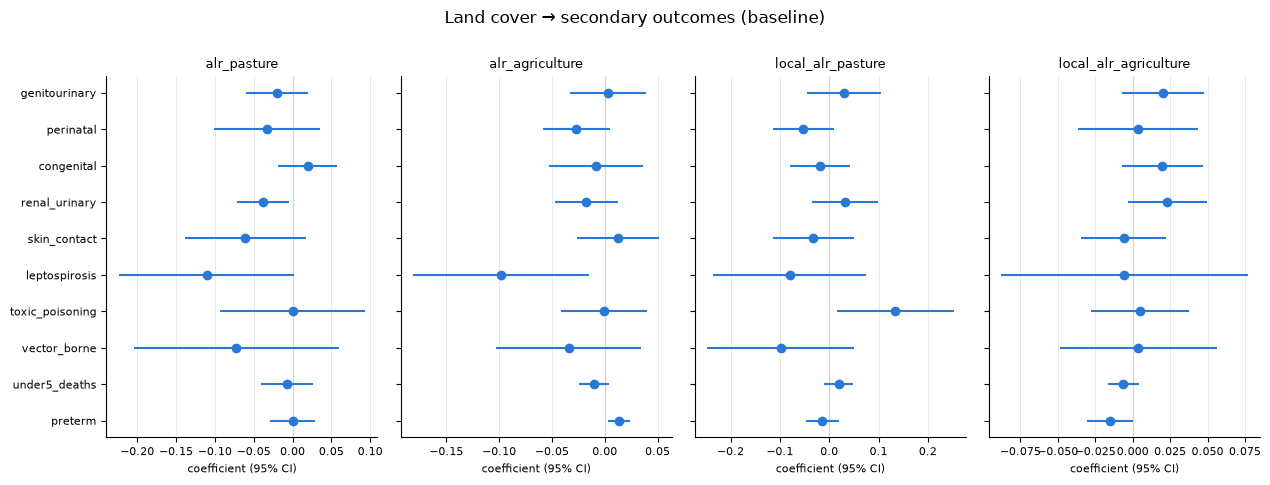

In [9]:
secondary_fits = fit_all(SECONDARY)
secondary = tidy(secondary_fits, "baseline")
coefficient_plot(secondary, ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"],
                 title="Land cover → secondary outcomes (baseline)")

**Reading the results (run of 2026-10-22).** 23 of 100 land-cover coefficients are significant at 5% (5 expected), but most involve
local urban land or unclassified farming, and the signs are mixed. Upstream pasture
lowers renal/urinary hospitalizations (−0.038, SE 0.017). Upstream agriculture lowers
leptospirosis (−0.10, 0.04; only 2,441 cases a year) and raises preterm births (+0.013,
0.005; 2012–2024). No secondary outcome shows an adverse upstream pasture effect.

## 5. Robustness

Primary and placebo outcomes under the alternatives in the decision table: OLS on
population-weighted log rates of positive counts, dropping 2020–21, upstream exposure
only, the utilization control (hospitalization outcomes), the upstream climate block,
municipality + biome×year FE, the current SIH system only (2008–2024), and municipalities
with upstream rings only.

spec                                        baseline  OLS log rate  drop 2020–21  upstream only  + utilization  + upstream climate  mun + biome×year FE  2008–2024  has upstream only
outcome              Coefficient                                                                                                                                                     
infectious_parasitic alr_pasture              -0.037        -0.044        -0.038         -0.002         -0.026              -0.037               -0.113     -0.049             -0.032
                     alr_agriculture          -0.031        -0.021        -0.031         -0.037         -0.014              -0.032               -0.044     -0.044             -0.033
                     local_alr_pasture         0.071         0.089         0.069            NaN          0.045               0.071                 0.12      0.065              0.064
                     local_alr_agriculture        -0        -0.016         0.006            NaN         -0.001                  -0                0.023      0.006                 -0
digestive            alr_pasture              -0.006         0.001        -0.005          0.004          0.002              -0.006               -0.035      0.001              -0.01
                     alr_agriculture           0.003            -0         0.004          0.006          0.011               0.003               -0.014      0.006             -0.003
                     local_alr_pasture         0.015         0.023         0.013            NaN         -0.003               0.014                0.005     -0.004              0.013
                     local_alr_agriculture    -0.002        -0.002        -0.001            NaN         -0.002              -0.001                0.013     -0.008                 -0
gastrointestinal     alr_pasture              -0.084        -0.085         -0.08          0.003         -0.094              -0.084               -0.041     -0.128             -0.083
                     alr_agriculture           -0.03        -0.013        -0.024         -0.014         -0.002               -0.03               -0.039     -0.075             -0.036
                     local_alr_pasture          0.16         0.264         0.153            NaN           0.16                0.16                0.301      0.202               0.14
                     local_alr_agriculture     0.027        -0.006         0.024            NaN          0.021               0.027                 0.05      0.032              0.029
infant_deaths        alr_pasture              -0.012        -0.018        -0.014         -0.002            NaN              -0.012               -0.036     -0.018             -0.014
                     alr_agriculture          -0.013        -0.015        -0.014         -0.019            NaN              -0.012               -0.019     -0.018             -0.013
                     local_alr_pasture          0.02         0.024         0.018            NaN            NaN                0.02                0.048      0.023              0.021
                     local_alr_agriculture    -0.008        -0.003        -0.008            NaN            NaN              -0.008                0.001      0.007             -0.009
low_birth_weight     alr_pasture              -0.001            -0            -0         -0.002            NaN              -0.001               -0.004         -0             -0.005
                     alr_agriculture           0.006         0.005         0.006          0.014            NaN               0.006                0.007      0.002              0.004
                     local_alr_pasture        -0.002         0.004        -0.001            NaN            NaN              -0.002               -0.003     -0.011             -0.002
                     local_alr_agriculture     0.011         0.011         0.011            NaN            NaN               0.011                0.005       0.01              0.

,coefficients,same_sign_as_baseline,significant_5pct
spec,,,
baseline,80,1,21
OLS log rate,80,0.9,21
drop 2020–21,80,0.975,19
upstream only,40,0.75,8
+ utilization,60,0.8333,15
+ upstream climate,80,0.9875,21
mun + biome×year FE,80,0.8375,22
2008–2024,80,0.825,17
has upstream only,80,0.9375,21


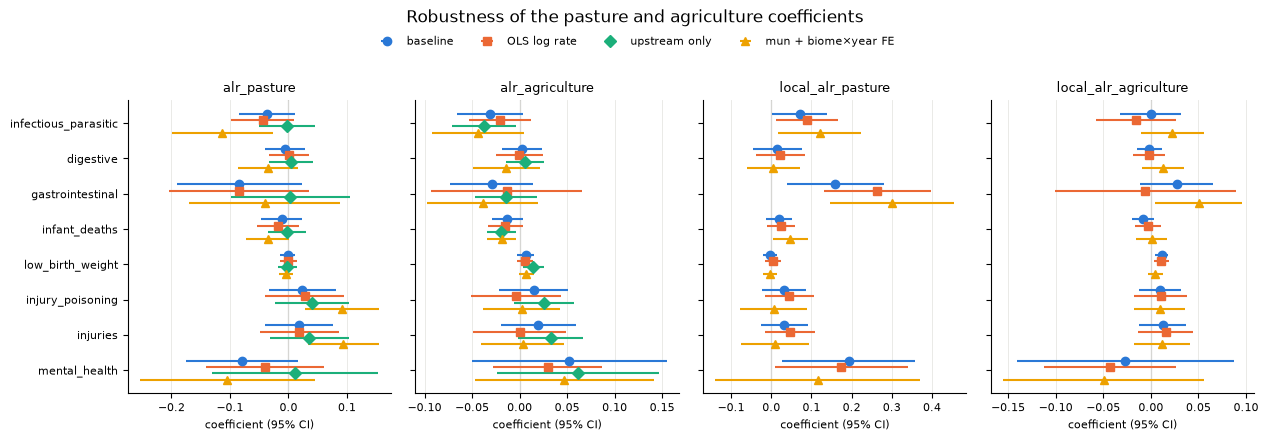

In [10]:
ROBUST_OUTCOMES = PRIMARY + PLACEBO
HOSPITALIZATION = [name for name in ROBUST_OUTCOMES if name in H.HOSPITALIZATION_OUTCOMES]
UPSTREAM_CLIMATE = list(H.UPSTREAM_CLIMATE_CONTROLS.values())
ROBUSTNESS_SPECS = {
    "OLS log rate": dict(method="ols"),
    "drop 2020–21": dict(data=df[~df["year"].isin(H.COVID_YEARS)]),
    "upstream only": dict(rhs=" + ".join(UPSTREAM + CONTROLS)),
    "+ utilization": dict(rhs=f"{RHS} + {H.UTILIZATION_CONTROL}"),
    "+ upstream climate": dict(rhs=" + ".join([RHS, *UPSTREAM_CLIMATE])),
    "mun + biome×year FE": dict(fe="mun_id + biome_year"),
    "2008–2024": dict(data=df[df["year"] >= H.SIH_FIRST_CURRENT_YEAR]),
    "has upstream only": dict(data=df[df["has_upstream"]]),
}
robustness = [main]
for spec, kwargs in ROBUSTNESS_SPECS.items():
    names = HOSPITALIZATION if spec == "+ utilization" else ROBUST_OUTCOMES
    robustness.append(tidy(fit_all(names, **kwargs), spec))
robustness = pd.concat(robustness, ignore_index=True)

KEY_TERMS = ["alr_pasture", "alr_agriculture", "local_alr_pasture", "local_alr_agriculture"]
key = robustness[robustness["Coefficient"].isin(KEY_TERMS)]
display(key.pivot_table(index=["outcome", "Coefficient"], columns="spec", values="Estimate", sort=False)
        [["baseline", *ROBUSTNESS_SPECS]].round(3))
baseline_sign = np.sign(main.set_index(["outcome", "Coefficient"])["Estimate"])
upstream_land_cover = robustness[robustness["Coefficient"].isin(UPSTREAM + LOCAL)]
display(upstream_land_cover.assign(
    same_sign=lambda t: np.sign(t["Estimate"]).to_numpy()
    == baseline_sign.reindex(pd.MultiIndex.from_frame(t[["outcome", "Coefficient"]])).to_numpy(),
    significant=lambda t: t["Pr(>|t|)"] < 0.05,
).groupby("spec", sort=False).agg(coefficients=("Estimate", "size"), same_sign_as_baseline=("same_sign", "mean"),
                                  significant_5pct=("significant", "sum")).loc[["baseline", *ROBUSTNESS_SPECS]])
coefficient_plot(robustness, KEY_TERMS, specs=["baseline", "OLS log rate", "upstream only", "mun + biome×year FE"],
                 title="Robustness of the pasture and agriculture coefficients")

**Reading the results (run of 2026-10-22).**
- **Sign agreement.** Signs agree with the baseline for 82–99% of the land-cover
  coefficients in every specification except upstream-only (75%). Without the local block
  the upstream terms absorb local change.
- **Biome×year FE.** This specification moves the estimates most: upstream pasture →
  infectious −0.11, and the injury placebo becomes positive and significant (+0.09,
  p = 0.004). State×year FE absorb state-level trends that biome×year leaves in, which
  supports the baseline choice.
- **Where pasture or agriculture becomes significant.** That happens 11 times in a primary
  outcome, mostly negative. The two positive cases are small: agriculture → LBW +0.014
  (upstream only) and → digestive +0.011 (with the utilization control), at most 0.65%
  per within-SD.
- **Small changes.** Dropping 2020–21, adding upstream climate, the 2008–2024 window and
  municipalities with upstream rings only all change little.

## 6. Distance bands

Separate upstream ALR terms for 0–50, 50–150 and 150–500 km (local block and controls as
in the baseline). Municipalities without rings in a band get 0 for it, absorbed by the
municipality FE (their reach is fixed over time), so each band is identified from the
municipalities that have it.

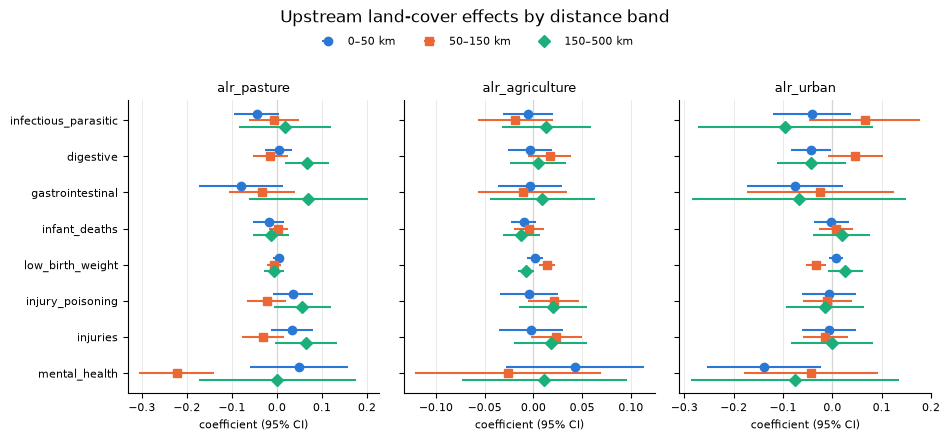

In [11]:
BANDED = [f"{regressor}__{band}" for band in H.DISTANCE_BANDS for regressor in UPSTREAM]
band_fits = fit_all(PRIMARY + PLACEBO, rhs=" + ".join(BANDED + LOCAL + CONTROLS))
bands = tidy(band_fits, "bands")

band_long = bands[bands["Coefficient"].isin(BANDED)].copy()
band_long[["regressor", "band"]] = band_long["Coefficient"].str.split("__", expand=True)
band_long["spec"] = band_long["band"].map({b: f"{lo}–{hi} km" for b, (lo, hi) in H.DISTANCE_BANDS.items()})
band_long["Coefficient"] = band_long["regressor"]
coefficient_plot(band_long, ["alr_pasture", "alr_agriculture", "alr_urban"],
                 specs=[f"{lo}–{hi} km" for lo, hi in H.DISTANCE_BANDS.values()],
                 title="Upstream land-cover effects by distance band")

**Reading the results (run of 2026-10-22).** 14 of 120 band coefficients are significant at 5% (6 expected), with no distance
gradient: far-band (150–500 km) "other" land raises the injury placebos (+0.05) as much
as infant deaths (+0.04). As in the pollution arm, the data cannot separate distances,
and the capped exposure stays the baseline.

## 7. Heterogeneity by biome

Biome-specific slopes for upstream pasture and agriculture (Pampa and Pantanal pooled);
the other regressors keep a common slope.

biome_group,Mata Atlântica,Cerrado,Caatinga,Amazônia,Pampa/Pantanal
municipalities,2693,1102,1096,502,169


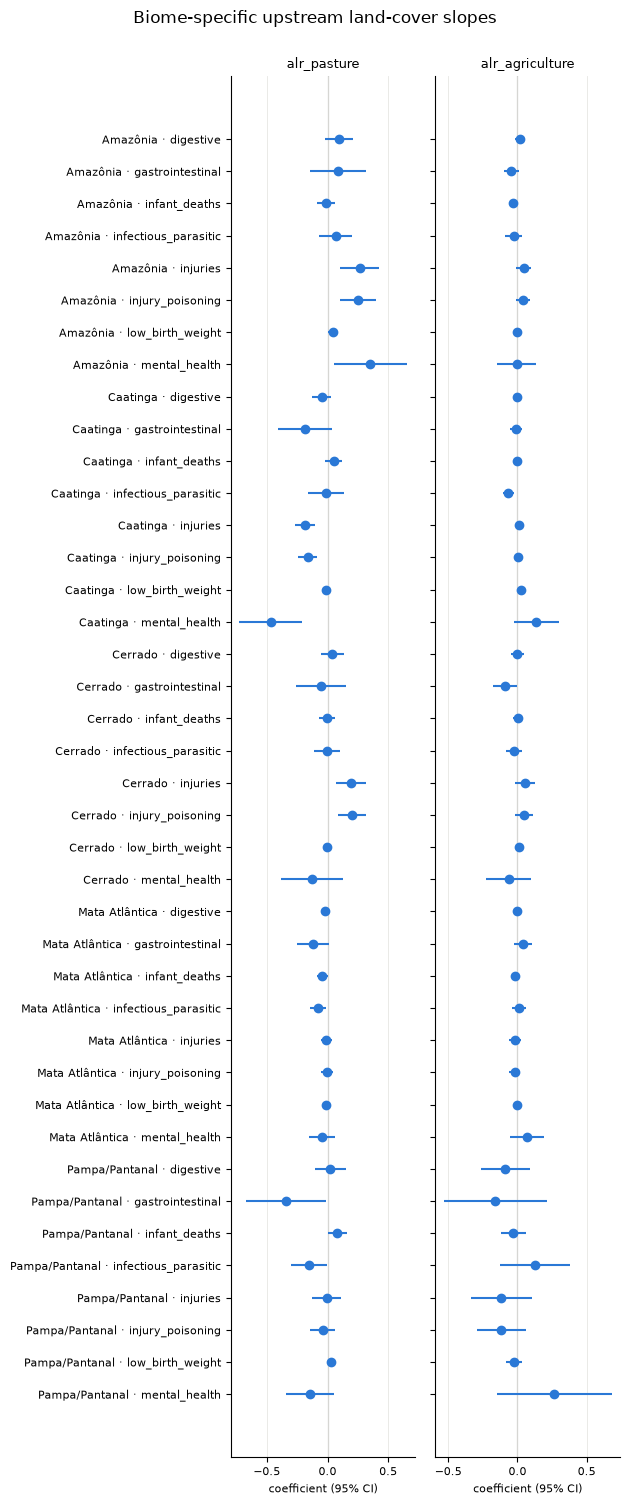

In [12]:
display(municipalities["biome_group"].value_counts().rename("municipalities").to_frame().T)
other_upstream = [r for r in UPSTREAM if r not in ("alr_pasture", "alr_agriculture")]
RHS_BIOME = " + ".join(["i(biome_group, alr_pasture)", "i(biome_group, alr_agriculture)"] + other_upstream + LOCAL + CONTROLS)
biome_fits = fit_all(PRIMARY + PLACEBO, rhs=RHS_BIOME)
biome = tidy(biome_fits, "by biome")

biome_long = biome[biome["Coefficient"].str.startswith("biome_group::")].copy()
parts = biome_long["Coefficient"].str.extract(r"biome_group::(?P<biome>.+):(?P<regressor>alr_\w+)$")
biome_long["Coefficient"] = parts["regressor"]
biome_long["outcome"] = parts["biome"] + " · " + biome_long["outcome"]
coefficient_plot(biome_long.sort_values("outcome"), ["alr_pasture", "alr_agriculture"], specs=["by biome"],
                 title="Biome-specific upstream land-cover slopes")

**Reading the results (run of 2026-10-22).** 17 of 80 biome slopes are significant at 5% (4 expected). The clearest pattern is in the
**placebo**: injury hospitalizations rise with upstream pasture in the Amazon (+0.25) and
the Cerrado (+0.20), the agricultural frontier, and fall in the Caatinga (−0.16).
Mental-health hospitalizations follow the same pattern. Water outcomes show no consistent
biome pattern (e.g. Mata Atlântica pasture → infectious −0.08, Amazon pasture → LBW
+0.05). Frontier pasture expansion goes with more injuries (occupational, violence),
which upstream water quality cannot explain.

## 8. Inference

### 8.1 Clustering level
Standard errors of the baseline fits under alternative clusterings, recomputed on the
same fits; ratios are relative to the Otto-3 baseline.

In [13]:
CLUSTERINGS = {"state": {"CRV1": "state"}, "Otto 3 (baseline)": VCOV, "Otto 4": {"CRV1": "otto_basin_l4"}}
rows = []
for outcome, model in main_fits.items():
    for label, vcov in CLUSTERINGS.items():
        model.vcov(vcov)
        table = model.tidy().loc[UPSTREAM + LOCAL]
        rows.append(table.assign(outcome=outcome, clustering=label, n_clusters=model._G[0]).reset_index())
    model.vcov(VCOV)  # restore the baseline inference
inference = pd.concat(rows, ignore_index=True)

standard_errors = inference.pivot_table(index=["outcome", "Coefficient"], columns="clustering", values="Std. Error")
se_ratio = standard_errors.div(standard_errors["Otto 3 (baseline)"], axis=0)
display(se_ratio[list(CLUSTERINGS)].describe(percentiles=[0.1, 0.5, 0.9]).T.round(2))
display(inference.groupby("clustering").agg(
    clusters=("n_clusters", "median"),
    significant_5pct=("Pr(>|t|)", lambda p: int((p < 0.05).sum())),
    tests=("Pr(>|t|)", "size"),
).loc[list(CLUSTERINGS)])

,count,mean,std,min,10%,50%,90%,max
clustering,,,,,,,,
state,80,1.06,0.2,0.6,0.76,1.07,1.32,1.45
Otto 3 (baseline),80,1,0,1,1,1,1,1
Otto 4,80,0.95,0.1,0.7,0.82,0.96,1.08,1.3


,clusters,significant_5pct,tests
clustering,,,
state,26,18,80
Otto 3 (baseline),217,21,80
Otto 4,821,23,80


**Reading the results (run of 2026-10-22).** State clustering (26 clusters) gives SEs 7% larger at the median, and Otto 4 4% smaller;
18, 21 and 23 of 80 coefficients are significant at 5% under state, Otto 3 and Otto 4. The
Otto-3 baseline sits between the two.

### 8.2 Wild-cluster score bootstrap

PPML has no demeaned OLS form to resample, so the restricted wild-cluster **score**
bootstrap (Kline and Santos 2012; `inference.poisson_score_bootstrap`, 9,999 Rademacher
draws over Otto-3 basins) tests each land-cover coefficient of the baseline fits and each
placebo difference of §3.1.

In [14]:
BOOT_REPS = 9_999
boot_rows = []
for family, fits, terms in [("baseline", main_fits, UPSTREAM + LOCAL), ("minus placebo", diff_fits, list(DIFF.values()))]:
    for outcome, model in fits.items():
        analytic = model.tidy()
        for term in terms:
            row = poisson_score_bootstrap(model, term, cluster="otto_basin_l3", reps=BOOT_REPS, seed=20261022)
            row["outcome"], row["family"] = outcome, family
            row["Estimate"] = analytic.loc[term, "Estimate"]
            row["p_analytic"] = analytic.loc[term, "Pr(>|t|)"]
            boot_rows.append(row)
bootstrap = pd.DataFrame(boot_rows)
bootstrap["Coefficient"] = bootstrap["Coefficient"].str.removesuffix("_diff")

display(bootstrap.groupby("family").agg(
    tests=("p_wcb", "size"),
    clusters=("n_clusters", "median"),
    analytic_5pct=("p_analytic", lambda p: int((p < 0.05).sum())),
    bootstrap_5pct=("p_wcb", lambda p: int((p < 0.05).sum())),
    bootstrap_1pct=("p_wcb", lambda p: int((p < 0.01).sum())),
))
display(bootstrap[(bootstrap["p_wcb"] < 0.05) | (bootstrap["p_analytic"] < 0.05)]
        .sort_values(["family", "p_wcb"])
        [["family", "outcome", "Coefficient", "Estimate", "p_analytic", "p_wcb", "n_clusters"]])

,tests,clusters,analytic_5pct,bootstrap_5pct,bootstrap_1pct
family,,,,,
baseline,80,217,21,16,8
minus placebo,50,217,8,6,4


,family,outcome,Coefficient,Estimate,p_analytic,p_wcb,n_clusters
18,baseline,digestive,local_alr_urban,0.1674,0.0005239,0,217
48,baseline,low_birth_weight,local_alr_urban,0.08266,3.617e-05,0,217
58,baseline,injury_poisoning,local_alr_urban,0.2269,2.992e-08,0,217
68,baseline,injuries,local_alr_urban,0.2597,1.184e-08,0,217
42,baseline,low_birth_weight,alr_farming_unclassified,-0.02474,1.093e-05,0.0002,217
74,baseline,mental_health,alr_other,0.1331,0.0002064,0.001,217
37,baseline,infant_deaths,local_alr_farming_unclassified,-0.03123,0.005735,0.009601,217
8,baseline,infectious_parasitic,local_alr_urban,-0.2568,0.001083,0.009701,217
49,baseline,low_birth_weight,local_alr_other,0.01208,0.00601,0.0127,217
46,baseline,low_birth_weight,local_alr_agriculture,0.01123,0.00238,0.0133,217


**Reading the results (run of 2026-10-22).**
- **Baseline.** 16 of 80 tests pass the score bootstrap at 5% (21 analytically).
  12 of them are local-block terms, 6 of those local urban (4 with p < 0.0001).
- **Upstream terms.** 4 of 40 pass (2 expected); they are the ones listed in §3.
- **Minus placebo.** 6 of 50 tests pass, all for local urban or "other" land. No upstream
  difference passes; the smallest p-values are 0.052 for agriculture and 0.053 for
  pasture → infectious, both negative.
- **p = 0.** No draw exceeded the observed statistic (p < 1e-4).

## 9. Results export

In [15]:
results = pd.concat([main.assign(family="baseline"), difference.assign(family="minus placebo"),
                     secondary.assign(family="secondary"), robustness[robustness["spec"] != "baseline"].assign(family="robustness"),
                     bands.assign(family="bands"), biome.assign(family="biome"),
                     inference.rename(columns={"clustering": "spec"}).assign(family="inference")], ignore_index=True)
results.to_csv(RESULTS_DIR / "coefficients.csv", index=False)
bootstrap.to_csv(RESULTS_DIR / "wild_cluster_bootstrap.csv", index=False)
print(f"{len(results):,} coefficient rows -> {RESULTS_DIR.relative_to(PROJECT_ROOT) / 'coefficients.csv'}")

1,672 coefficient rows -> output/analysis/health/coefficients.csv
